# Hourly Traffic Volume Forecasting — I-94, Minneapolis–St Paul

**Author:** Marta Cruz · **Origin:** internship case study at BI4ALL (2023), revisited and rebuilt in 2026

## Business question
Predict hourly traffic volume on a highway segment, given the calendar, holidays and weather,
so that an operator can anticipate congestion and plan resources.

## Dataset
UCI *Metro Interstate Traffic Volume* (CC BY 4.0): hourly westbound I-94 traffic counts from a
Minnesota DoT station between Minneapolis and St Paul, Oct 2012 – Sep 2018, joined with
OpenWeatherMap weather and US holidays.

## What this notebook does differently from the 2023 version
1. **Data quality first.** Profiles completeness and consistency before modelling, and documents every fix.
2. **The target is never imputed.** Missing hours stay missing instead of being back-filled.
3. **Holidays are applied to the whole day**, not only to the midnight row.
4. **Calendar features** (hour, weekday, month) are added explicitly.
5. **Baselines first.** Every model must beat a naive forecast to be worth anything.
6. **Ablation and error analysis** show which inputs actually matter, and where the model fails.

## 1. Setup

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from xgboost import XGBRegressor

RANDOM_STATE = 2
DATA_PATH = "data/Metro_Interstate_Traffic_Volume.csv.gz"   # also accepts the original .csv
TEST_START = "2018-01-01"

pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")
print("python", sys.version.split()[0], "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

python 3.12.3 | pandas 3.0.6 | scikit-learn 1.9.1 | xgboost 3.4.1


In [2]:
def wape(actual, predicted):
    """Weighted Absolute Percentage Error: total absolute error / total actual volume, in %.
    Chosen over MAPE because traffic can be (near) zero at night, which makes MAPE explode."""
    actual, predicted = np.asarray(actual, float), np.asarray(predicted, float)
    return np.abs(actual - predicted).sum() / actual.sum() * 100


def mae(actual, predicted):
    return np.mean(np.abs(np.asarray(actual, float) - np.asarray(predicted, float)))

## 2. Load the raw data

In [3]:
raw = pd.read_csv(DATA_PATH)
# pandas reads the string "None" in the holiday column as missing, which is what we want.
raw["date_time"] = pd.to_datetime(raw["date_time"], format="mixed", dayfirst=False)
print(raw.shape)
raw.head()

(48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.00,0.00,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.00,0.00,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.00,0.00,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.00,0.00,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.00,0.00,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


## 3. Data quality profile
Before any modelling: is the data complete, consistent and fit for an hourly forecast?
Each check below records the problem, its size and the decision taken.

In [4]:
full_range = pd.date_range(raw["date_time"].min(), raw["date_time"].max(), freq="h")
dup_rows = raw.duplicated(subset="date_time").sum()
unique_hours = raw["date_time"].nunique()
zero_kelvin = (raw["temp"] == 0).sum()
rain_outliers = (raw["rain_1h"] > 1000).sum()
holiday_rows = raw["holiday"].notna().sum()
holiday_hours = raw.loc[raw["holiday"].notna(), "date_time"].dt.hour.value_counts().to_dict()

quality = pd.DataFrame([
    ["Duplicate timestamps", dup_rows,
     "Several weather descriptions per hour, traffic identical", "Keep first row per hour"],
    ["Missing hours (completeness)", len(full_range) - unique_hours,
     f"{(len(full_range) - unique_hours) / len(full_range):.1%} of the hourly grid has no reading", "Keep as missing, never impute the target"],
    ["Temperature = 0 K", zero_kelvin, "Physically impossible, sensor error", "Set to NaN (tree model handles NaN)"],
    ["rain_1h > 1000 mm", rain_outliers, "One impossible reading (9,831 mm in an hour)", "Set to NaN"],
    ["snow_1h non-zero", (raw["snow_1h"] > 0).sum(),
     "Snow amount almost never recorded, even during blizzards", "Treat snow amount as unreliable; rely on weather_main"],
    ["Holiday label", holiday_rows, f"Only on these hours of the day: {holiday_hours}", "Propagate the label to the whole day"],
], columns=["check", "rows affected", "finding", "decision"])
quality

,check,rows affected,finding,decision
0,Duplicate timestamps,7629,"Several weather descriptions per hour, traffic...",Keep first row per hour
1,Missing hours (completeness),11976,22.8% of the hourly grid has no reading,"Keep as missing, never impute the target"
2,Temperature = 0 K,10,"Physically impossible, sensor error",Set to NaN (tree model handles NaN)
3,rain_1h > 1000 mm,1,"One impossible reading (9,831 mm in an hour)",Set to NaN
4,snow_1h non-zero,63,"Snow amount almost never recorded, even during...",Treat snow amount as unreliable; rely on weath...
5,Holiday label,61,Only on these hours of the day: {0: 61},Propagate the label to the whole day


### 3.1 Where are the missing hours?

In [5]:
hourly = raw.drop_duplicates("date_time").set_index("date_time").reindex(full_range)
hourly.index.name = "date_time"
missing = hourly["traffic_volume"].isna()
run_id = (missing != missing.shift()).cumsum()
gaps = (hourly[missing].reset_index()
        .groupby(run_id[missing].values)["date_time"]
        .agg(start="min", end="max", hours="count")
        .sort_values("hours", ascending=False))
gaps.head(5)

,start,end,hours
1792,2014-08-08 02:00:00,2015-06-11 19:00:00,7386
1328,2013-10-27 02:00:00,2013-11-06 03:00:00,242
1804,2015-06-14 21:00:00,2015-06-19 17:00:00,117
1566,2014-04-29 09:00:00,2014-05-04 04:00:00,116
2048,2015-10-23 12:00:00,2015-10-27 07:00:00,92


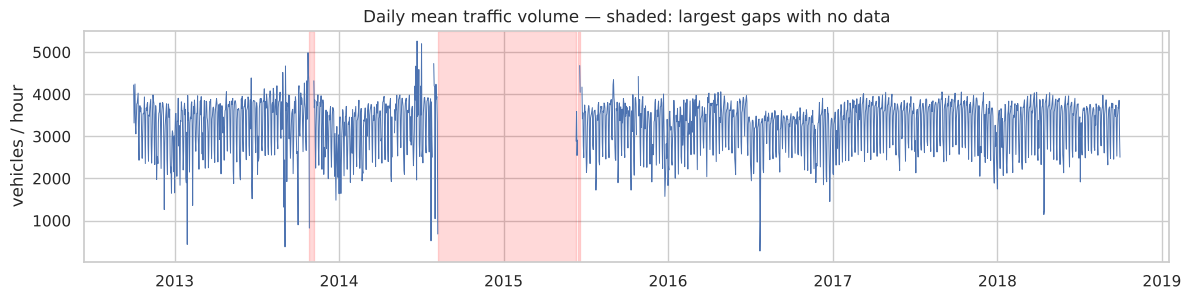

In [6]:
fig, ax = plt.subplots(figsize=(14, 3))
daily = hourly["traffic_volume"].resample("D").mean()
ax.plot(daily.index, daily.values, lw=0.7)
for _, g in gaps.head(3).iterrows():
    ax.axvspan(g["start"], g["end"], color="red", alpha=0.15)
ax.set_title("Daily mean traffic volume — shaded: largest gaps with no data")
ax.set_ylabel("vehicles / hour")
plt.show()

**Why this matters.** The largest gap is about ten months long (Aug 2014 – Jun 2015).
The 2023 version filled missing hours with `bfill()` on *every* column, including `traffic_volume`.
That copied a single value into thousands of consecutive hours, so roughly a quarter of the
training rows were synthetic flat lines, and the lag features built from them were fake too.
Here, missing hours stay missing: they are excluded as training targets, and lag features
that point into a gap are left as NaN.

## 4. Cleaning

In [7]:
df = hourly.copy()
df["is_observed"] = df["traffic_volume"].notna()

df["temp"] = df["temp"].replace(0, np.nan)
df.loc[df["rain_1h"] > 1000, "rain_1h"] = np.nan
df = df.drop(columns="weather_description")   # finer-grained duplicate of weather_main
df["weather_main"] = df["weather_main"].astype("category")

holiday_days = df.index[df["holiday"].notna()].normalize().unique()
df["is_holiday"] = df.index.normalize().isin(holiday_days).astype(int)
df = df.drop(columns="holiday")

print(f"Holiday days: {len(holiday_days)}  |  hours flagged as holiday: {df['is_holiday'].sum():,}")

Holiday days: 53  |  hours flagged as holiday: 1,272


## 5. Exploratory analysis

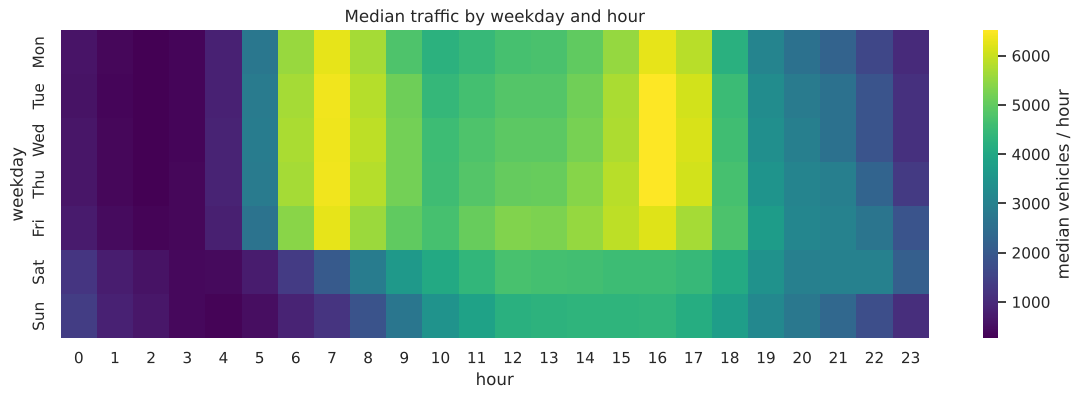

In [8]:
obs = df[df["is_observed"]].copy()
obs["hour"], obs["weekday"] = obs.index.hour, obs.index.day_name().str[:3]
order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
pivot = obs.pivot_table(index="weekday", columns="hour", values="traffic_volume", aggfunc="median").loc[order]

fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(pivot, cmap="viridis", ax=ax, cbar_kws={"label": "median vehicles / hour"})
ax.set_title("Median traffic by weekday and hour")
plt.show()

The weekly rhythm dominates: commuter peaks around 7h and 16–17h on weekdays, a single
broad midday hump at weekends, and near-empty roads at night. Any good model must capture this.

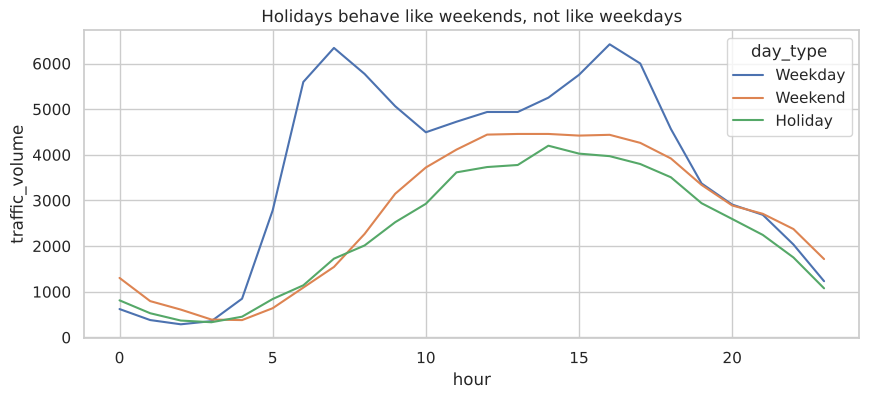

In [9]:
obs["day_type"] = np.select(
    [obs["is_holiday"] == 1, obs.index.dayofweek >= 5], ["Holiday", "Weekend"], "Weekday")
fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=obs, x="hour", y="traffic_volume", hue="day_type",
             estimator="median", errorbar=None, ax=ax)
ax.set_title("Holidays behave like weekends, not like weekdays")
plt.show()

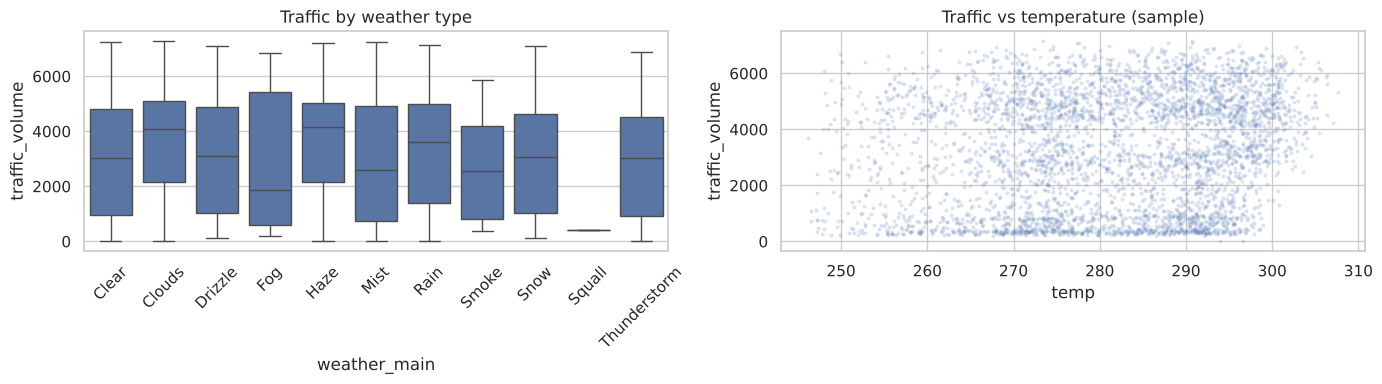

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=obs, x="weather_main", y="traffic_volume", ax=axes[0])
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_title("Traffic by weather type")
sns.scatterplot(data=obs.sample(4000, random_state=RANDOM_STATE), x="temp", y="traffic_volume",
                alpha=0.2, s=8, ax=axes[1])
axes[1].set_title("Traffic vs temperature (sample)")
plt.tight_layout()
plt.show()

Weather shows weak, mostly indirect relationships. Most of the spread within each weather type
comes from the time of day, not the weather itself. This is checked formally in the ablation below.

## 6. Feature engineering
- **Calendar:** hour, day of week, month, weekend flag, holiday flag.
- **Lags:** traffic 1, 2 and 4 weeks earlier, at the same hour. Multiples of 7 days keep the
  weekday aligned. (The 2023 version used 30 days, which compares a Monday with a Wednesday.)
- Because the hourly grid is complete, `shift(168)` is exactly 168 hours earlier. If that hour
  was not observed, the lag is NaN rather than a fabricated value.

**Forecast horizon:** with a 1-week lag, the model can forecast at most 7 days ahead.
The calendar-only model has no such limit.

In [11]:
df["hour"] = df.index.hour
df["dayofweek"] = df.index.dayofweek
df["month"] = df.index.month
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)
for weeks in (1, 2, 4):
    df[f"lag_{weeks}w"] = df["traffic_volume"].shift(weeks * 168)

CALENDAR = ["hour", "dayofweek", "month", "is_weekend", "is_holiday"]
WEATHER = ["temp", "rain_1h", "snow_1h", "clouds_all", "weather_main"]
LAGS = ["lag_1w", "lag_2w", "lag_4w"]
TARGET = "traffic_volume"

## 7. Train / test split
Chronological split: train on everything before 2018, test on 2018.
Only observed hours are used as targets in both sets.

In [12]:
model_df = df[df["is_observed"]]
train = model_df[model_df.index < TEST_START]
test = model_df[model_df.index >= TEST_START]
y_train, y_test = train[TARGET], test[TARGET]
print(f"train: {len(train):,} rows ({train.index.min():%Y-%m-%d} → {train.index.max():%Y-%m-%d})")
print(f"test:  {len(test):,} rows ({test.index.min():%Y-%m-%d} → {test.index.max():%Y-%m-%d})")

train: 34,042 rows (2012-10-02 → 2017-12-31)
test:  6,533 rows (2018-01-01 → 2018-09-30)


## 8. Baselines
A model is only useful if it beats something simple. Two baselines:
- **Naive seasonal:** traffic at the same hour one week earlier.
- **Weekly profile:** median traffic for each weekday × hour, learned from the training set.

In [13]:
results = []

def record(name, pred, subset=None):
    a, p = (y_test, pred) if subset is None else (y_test[subset], np.asarray(pred)[subset])
    results.append({"model": name, "test_WAPE_%": wape(a, p), "test_MAE": mae(a, p)})

has_lag = test["lag_1w"].notna().to_numpy()
record("Baseline: same hour last week", test["lag_1w"].to_numpy(), subset=has_lag)

profile = train.groupby(["dayofweek", "hour"])[TARGET].median()
record("Baseline: weekday × hour median",
       profile.reindex(pd.MultiIndex.from_arrays([test["dayofweek"], test["hour"]])).to_numpy())
pd.DataFrame(results)

,model,test_WAPE_%,test_MAE
0,Baseline: same hour last week,10.15,338.00
1,Baseline: weekday × hour median,7.59,252.25


## 9. Hyperparameter tuning (XGBoost)
`TimeSeriesSplit` keeps validation folds in the future of their training folds.
A one-week `gap` stops the lag features from leaking information across the fold boundary.

In [14]:
FEATURES = CALENDAR + WEATHER + LAGS
tscv = TimeSeriesSplit(n_splits=5, gap=168)

xgb_search = GridSearchCV(
    XGBRegressor(tree_method="hist", enable_categorical=True, subsample=0.8,
                 colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={"n_estimators": [300, 600], "max_depth": [4, 6, 8], "learning_rate": [0.05, 0.1]},
    cv=tscv, scoring="neg_mean_absolute_error", n_jobs=1,
)
xgb_search.fit(train[FEATURES], y_train)
BEST_XGB = xgb_search.best_params_
print("best params:", BEST_XGB, "| CV MAE:", round(-xgb_search.best_score_, 1))
(pd.DataFrame(xgb_search.cv_results_)
   .sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score"]].head(5))

best params: {'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 300} | CV MAE: 262.9


,params,mean_test_score,std_test_score
2,"{'learning_rate': 0.05, 'max_depth': 6, 'n_est...",-262.92,21.27
4,"{'learning_rate': 0.05, 'max_depth': 8, 'n_est...",-264.00,20.18
3,"{'learning_rate': 0.05, 'max_depth': 6, 'n_est...",-267.17,21.71
5,"{'learning_rate': 0.05, 'max_depth': 8, 'n_est...",-268.95,19.91
8,"{'learning_rate': 0.1, 'max_depth': 6, 'n_esti...",-271.20,25.01


## 10. Ablation: which inputs actually matter?
The same tuned model is retrained on different feature sets. This answers the original
business question directly: how much do weather and holidays help?

In [15]:
def fit_xgb(features):
    m = XGBRegressor(tree_method="hist", enable_categorical=True, subsample=0.8, colsample_bytree=0.8,
                     random_state=RANDOM_STATE, n_jobs=-1, **BEST_XGB)
    m.fit(train[features], y_train)
    return m

feature_sets = {
    "XGB: weather + holiday only": WEATHER + ["is_holiday"],
    "XGB: calendar only": CALENDAR,
    "XGB: calendar + weather": CALENDAR + WEATHER,
    "XGB: calendar + lags": CALENDAR + LAGS,
    "XGB: calendar + weather + lags": CALENDAR + WEATHER + LAGS,
}
models = {}
for name, feats in feature_sets.items():
    models[name] = fit_xgb(feats)
    record(name, models[name].predict(test[feats]))

rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1)
rf_feats = [f for f in CALENDAR + LAGS]          # RF in scikit-learn needs numeric, NaN-free input
rf_train = train[rf_feats].fillna(-1)
rf.fit(rf_train, y_train)
record("Random Forest: calendar + lags", rf.predict(test[rf_feats].fillna(-1)))

summary = pd.DataFrame(results).sort_values("test_WAPE_%").reset_index(drop=True)
summary

,model,test_WAPE_%,test_MAE
0,XGB: calendar only,6.66,221.39
1,XGB: calendar + weather,6.74,224.13
2,XGB: calendar + weather + lags,6.77,224.90
3,XGB: calendar + lags,6.89,228.91
4,Random Forest: calendar + lags,7.12,236.76
5,Baseline: weekday × hour median,7.59,252.25
6,Baseline: same hour last week,10.15,338.00
7,XGB: weather + holiday only,47.97,"1,594.32"


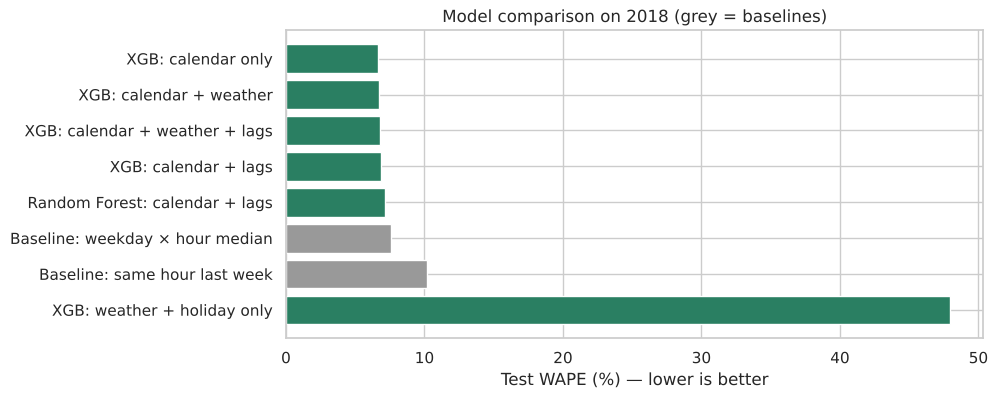

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
plot = summary.sort_values("test_WAPE_%", ascending=False)
colors = ["#999999" if m.startswith("Baseline") else "#2a7f62" for m in plot["model"]]
ax.barh(plot["model"], plot["test_WAPE_%"], color=colors)
ax.set_xlabel("Test WAPE (%) — lower is better")
ax.set_title("Model comparison on 2018 (grey = baselines)")
plt.show()

## 11. Final model and error analysis
The calendar-only model is the most accurate *and* the simplest. It also needs no recent traffic
or weather data, so it can forecast any date in the future, which is exactly the original goal of
predicting traffic "for a specific time period". It is chosen as the final model.

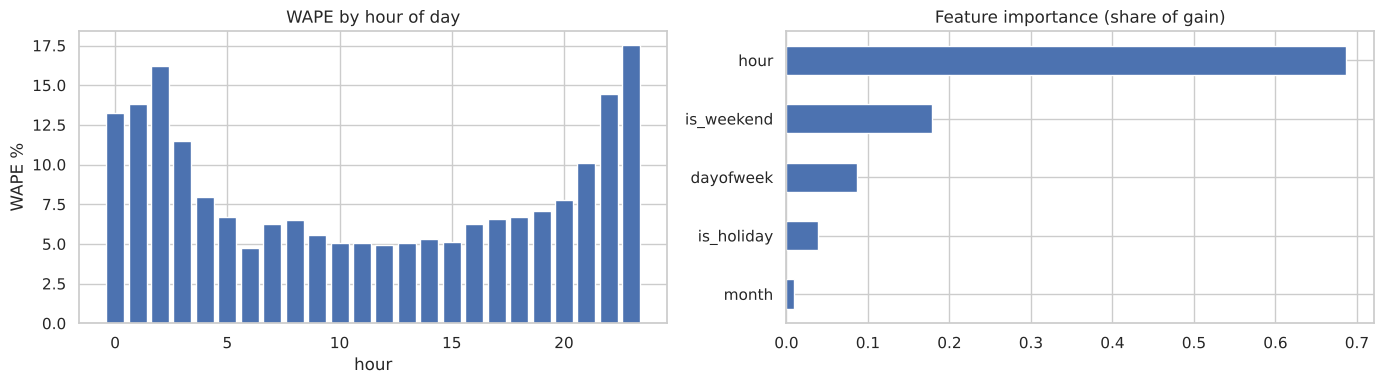

In [17]:
FINAL_NAME = "XGB: calendar only"
final = models[FINAL_NAME]
pred = pd.Series(final.predict(test[CALENDAR]), index=test.index)
err = pd.DataFrame({"actual": y_test, "pred": pred})
err["abs_err"] = (err["actual"] - err["pred"]).abs()
err["hour"] = err.index.hour

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_hour = err.groupby("hour").apply(lambda g: wape(g["actual"], g["pred"]))
axes[0].bar(by_hour.index, by_hour.values)
axes[0].set_title("WAPE by hour of day")
axes[0].set_xlabel("hour"); axes[0].set_ylabel("WAPE %")

imp = pd.Series(final.get_booster().get_score(importance_type="gain"))
(imp / imp.sum()).sort_values().plot.barh(ax=axes[1])
axes[1].set_title("Feature importance (share of gain)")
plt.tight_layout()
plt.show()

In [18]:
daily = err.resample("D")[["actual", "abs_err"]].sum()
daily = daily[daily["actual"] > 0]
daily["daily_WAPE_%"] = daily["abs_err"] / daily["actual"] * 100
daily["weekday"] = daily.index.day_name()
daily.sort_values("daily_WAPE_%", ascending=False).head(8)

,actual,abs_err,daily_WAPE_%,weekday
date_time,,,,
2018-04-14,"27,454.00","43,806.83",159.56,Saturday
2018-04-15,"29,720.00","30,535.01",102.74,Sunday
2018-01-01,"41,984.00","22,300.03",53.12,Monday
2018-01-22,"51,036.00","25,174.10",49.33,Monday
2018-03-05,"56,949.00","27,236.20",47.83,Monday
2018-04-03,"65,254.00","23,614.84",36.19,Tuesday
2018-01-11,"65,681.00","18,894.06",28.77,Thursday
2018-01-23,"62,574.00","17,123.06",27.36,Tuesday


The two worst days, 14–15 April 2018, coincide with a major spring blizzard: traffic fell to about
half of a normal weekend. The model could not see it coming because the weather feed failed too:
`weather_main` says *Snow* for most hours, but `snow_1h` reads **0.0 mm** for the whole storm.
This is a source-data problem, not a modelling problem, and the fix belongs upstream
(a better precipitation source), not in more hyperparameter tuning.

In [19]:
storm = raw[(raw["date_time"] >= "2018-04-13") & (raw["date_time"] < "2018-04-16")]
storm.groupby(storm["date_time"].dt.date).agg(
    traffic_total=("traffic_volume", "sum"),
    snow_1h_total=("snow_1h", "sum"),
    hours_labelled_snow=("weather_main", lambda s: (s == "Snow").sum()),
)

,traffic_total,snow_1h_total,hours_labelled_snow
date_time,,,
2018-04-13,169506,0.00,6
2018-04-14,82048,0.00,23
2018-04-15,68343,0.00,24


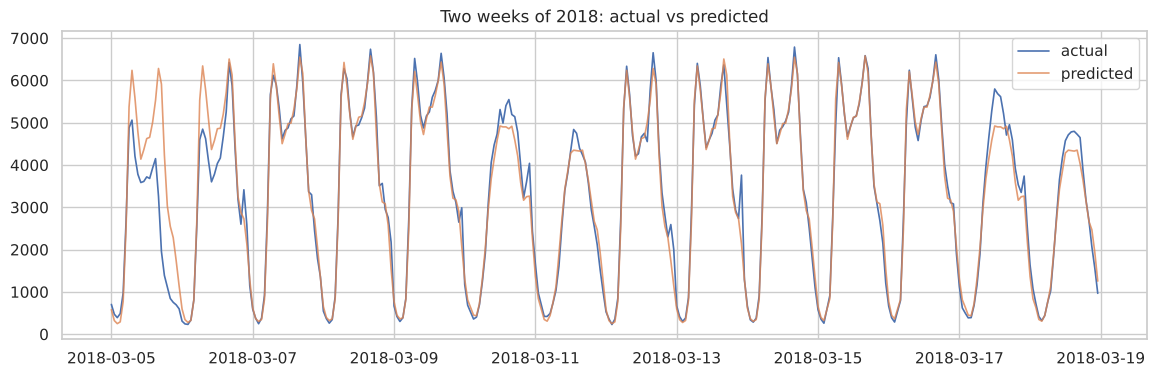

In [20]:
week = err.loc["2018-03-05":"2018-03-18"]
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(week.index, week["actual"], label="actual", lw=1.2)
ax.plot(week.index, week["pred"], label="predicted", lw=1.2, alpha=0.8)
ax.set_title("Two weeks of 2018: actual vs predicted")
ax.legend()
plt.show()

## 12. Conclusions
1. **Data quality drove the results more than the algorithm.** Not imputing the target and
   fixing the holiday labels mattered more than any hyperparameter.
2. **Traffic is mostly a calendar problem.** A model using only the hour, weekday, month and
   holiday flags is already far better than the 2023 model, and even the simple weekday × hour
   median beats it.
3. **Weather and lags add nothing on average.** Weather alone is a poor predictor, and adding
   weather or past traffic to the calendar model slightly *worsens* the test error. The simplest model wins.
   Weather only matters on unusual days (storms, snow), which is where the largest errors remain.
4. **Biggest remaining errors** are at night (low volumes, so small absolute errors become large
   relative ones) and on unusual days (events, incidents, irregular holidays).

## 13. Limitations and next steps
- The weather inputs are *observed* weather. In a real forecast you would only have a weather
  *forecast*, so the deployable model should be tested with forecast-quality inputs.
- Holidays come from a fixed list; school holidays, sports events and road works are missing
  and probably explain several of the worst days.
- Next steps: prediction intervals (quantile regression), event calendars, and monitoring
  data freshness so that gaps like the ten-month outage are caught early.

## Appendix: the 2023 pipeline, reproduced
For transparency, this reproduces the original approach on the same public data: back-fill every
column (including the target), holiday flag on midnight rows only, no calendar features,
30-day and 7-day lags, and a Random Forest with the 2023 settings.

In [21]:
old = raw.drop_duplicates("date_time").set_index("date_time").reindex(full_range)
was_missing = old["traffic_volume"].isna()
old["holiday"] = old["holiday"].notna().astype(int)        # midnight rows only, as in 2023
old["temp"] = old["temp"].replace(0, np.nan)
old = old.bfill()                                           # the problematic step
old.loc[old["rain_1h"] > 1000, "rain_1h"] = old["rain_1h"].median()
old["weather_main"] = old["weather_main"].astype("category").cat.codes
old["traffic_month_ago"] = old["traffic_volume"].shift(720)
old["traffic_week_ago"] = old["traffic_volume"].shift(168)
old = old[old.index > "2012-11-01 08:00"]
old_feats = ["holiday", "temp", "rain_1h", "snow_1h", "clouds_all", "weather_main",
             "traffic_month_ago", "traffic_week_ago"]
old_train, old_test = old[old.index < TEST_START], old[old.index >= TEST_START]
print(f"share of 2023 training rows with an invented target: {was_missing[old_train.index].mean():.1%}")

rf_2023 = RandomForestRegressor(n_estimators=200, max_depth=20, max_features="sqrt", min_samples_leaf=7,
                                min_samples_split=30, random_state=RANDOM_STATE, n_jobs=-1)
rf_2023.fit(old_train[old_feats], old_train["traffic_volume"])
real = ~was_missing[old_test.index].to_numpy()
p = rf_2023.predict(old_test[old_feats])
print(f"2023 pipeline, test WAPE on real 2018 hours: {wape(old_test['traffic_volume'][real], p[real]):.2f}%")
print(f"final 2026 model, test WAPE:                 {summary.set_index('model').loc[FINAL_NAME, 'test_WAPE_%']:.2f}%")

share of 2023 training rows with an invented target: 26.3%


2023 pipeline, test WAPE on real 2018 hours: 13.19%
final 2026 model, test WAPE:                 6.66%


In [22]:
summary.to_csv("results/model_comparison.csv", index=False)
print("saved results/model_comparison.csv")

saved results/model_comparison.csv
